<a href="https://colab.research.google.com/github/24cse025srutipatnaik/DMDW-Assignments/blob/main/Assignment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [5]:
data=pd.read_csv('/content/balance-scale.csv')
print("First five records:")
print(data.head())
print("Last few records")
print(data.tail())

First five records:
  Class  L-Weight  L-Distance  R-Weight  R-Distance
0     B         1           1         1           1
1     R         1           1         1           2
2     R         1           1         1           3
3     R         1           1         1           4
4     R         1           1         1           5
Last few records
    Class  L-Weight  L-Distance  R-Weight  R-Distance
620     L         5           5         5           1
621     L         5           5         5           2
622     L         5           5         5           3
623     L         5           5         5           4
624     B         5           5         5           5


In [6]:
X=data.iloc[: ,1:5]
Y=data.iloc[: ,0]

In [7]:
print("\nInput Features:")
print(X.head())

print("\ntarget variable")
print(Y.head())


Input Features:
   L-Weight  L-Distance  R-Weight  R-Distance
0         1           1         1           1
1         1           1         1           2
2         1           1         1           3
3         1           1         1           4
4         1           1         1           5

target variable
0    B
1    R
2    R
3    R
4    R
Name: Class, dtype: object


In [8]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.3,random_state=42)

In [9]:
#create Gaussian Naive Bayes model
model=GaussianNB()

#Train the model using training data
model.fit(X_train,Y_train)

GaussianNB()

In [10]:
print(model.theta_)
print(model.var_)

[[3.12903226 3.         3.12903226 3.        ]
 [3.625      3.61538462 2.40384615 2.42788462]
 [2.37878788 2.38383838 3.63131313 3.65656566]]
[[1.85431842 2.12903226 2.37044745 1.61290323]
 [1.41706731 1.5443787  1.85613906 1.75441476]
 [1.77066116 1.751658   1.52568616 1.41740639]]


In [11]:
y_pred=model.predict(X_test)

In [12]:
cm=confusion_matrix(Y_test,y_pred)
print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[ 0 13  5]
 [ 0 80  0]
 [ 0  3 87]]


In [13]:
accuracy=accuracy_score(Y_test,y_pred)
print("\nAccuracy Score:")
print(accuracy*100)


Accuracy Score:
88.82978723404256


In [14]:

print("\nClassification Report")
print(classification_report(Y_test,y_pred))


Classification Report
              precision    recall  f1-score   support

           B       0.00      0.00      0.00        18
           L       0.83      1.00      0.91        80
           R       0.95      0.97      0.96        90

    accuracy                           0.89       188
   macro avg       0.59      0.66      0.62       188
weighted avg       0.81      0.89      0.84       188



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


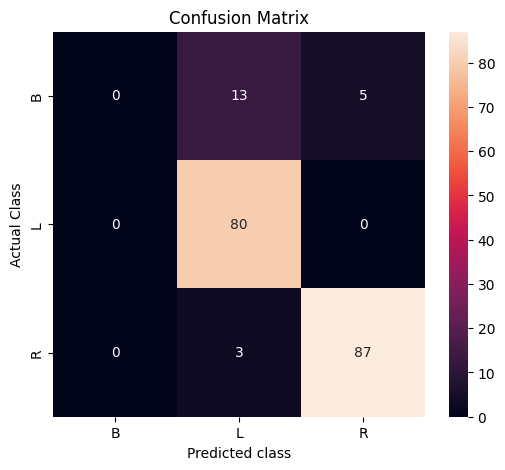

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt="d",xticklabels=model.classes_,yticklabels=model.classes_)
plt.title("Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual Class")
plt.show()